# AIML Lab Exercise 9: Naïve Bayesian Classifier
**Dataset:** Pima Indians Diabetes Dataset (diabetes.csv)

This notebook implements the **Gaussian Naïve Bayes classifier from scratch** for a training dataset stored as a `.CSV` file, and computes its accuracy on a separate test set. The task is to predict whether a patient has diabetes (`Outcome` = 1) from 8 medical measurements. The from-scratch result is verified against scikit-learn's `GaussianNB`.

## 1. Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the dataset from the CSV file

In [2]:
df = pd.read_csv('diabetes.csv')
print("Dataset loaded successfully! Shape:", df.shape)
df.info()
display(df.head())
display(df.describe())
print("Class distribution:\n", df['Outcome'].value_counts())

Dataset loaded successfully! Shape: (768, 9)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Class distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


## 3. Handle invalid zero values
In this dataset, a value of **0** for `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` or `BMI` is medically impossible — it actually means the value is **missing**. We replace these zeros with the **median** of the column.

In [3]:
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("Number of zero (missing) values BEFORE:\n", (df[zero_cols] == 0).sum())

for col in zero_cols:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

print("\nNumber of zero (missing) values AFTER:\n", (df[zero_cols] == 0).sum())

Number of zero (missing) values BEFORE:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Number of zero (missing) values AFTER:
 Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


## 4. Split the data into training and test sets

In [4]:
features = [c for c in df.columns if c != 'Outcome']
X = df[features].values
y = df['Outcome'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Split {len(df)} rows into train = {len(X_train)} rows and test = {len(X_test)} rows")

Split 768 rows into train = 537 rows and test = 231 rows


## 5. Theory: Bayes' rule and the Naïve Bayes model
**Bayes' theorem:**

$$P(C \mid X) = \frac{P(X \mid C)\,P(C)}{P(X)}$$

- **P(C)** — prior probability of class C
- **P(X | C)** — likelihood of the features given the class
- **P(C | X)** — posterior probability of the class given the features

The **naïve** assumption is that the features are **conditionally independent** given the class:

$$P(X \mid C) = \prod_{i=1}^{n} P(x_i \mid C)$$

For continuous features we assume a **Gaussian (normal) class-conditional distribution**, whose mean μ and standard deviation σ are the **maximum likelihood estimates** from the training data:

$$P(x_i \mid C) = \frac{1}{\sqrt{2\pi\sigma_C^2}}\exp\left(-\frac{(x_i - \mu_C)^2}{2\sigma_C^2}\right)$$

The predicted class is the one with the **largest posterior**. P(X) is the same for all classes, so it can be ignored. We add **logarithms** instead of multiplying probabilities to avoid numerical underflow.

## 6. Train the classifier: compute prior, mean and standard deviation for each class

In [5]:
def summarize_by_class(X, y):
    summaries = {}
    for c in np.unique(y):
        X_c = X[y == c]
        summaries[c] = {
            'prior': len(X_c) / len(X),
            'mean': X_c.mean(axis=0),
            'std': X_c.std(axis=0, ddof=1),
        }
    return summaries

model = summarize_by_class(X_train, y_train)

for c, s in model.items():
    print(f"Class {c}: prior P(C={c}) = {s['prior']:.4f}")
display(pd.DataFrame({f'Mean (class {c})': s['mean'] for c, s in model.items()} |
                     {f'Std (class {c})': s['std'] for c, s in model.items()}, index=features).round(3))

Class 0: prior P(C=0) = 0.6518
Class 1: prior P(C=1) = 0.3482


,Mean (class 0),Mean (class 1),Std (class 0),Std (class 1)
Pregnancies,3.317,4.941,2.996,3.712
Glucose,110.689,141.920,23.755,29.787
BloodPressure,70.691,75.102,12.035,11.977
SkinThickness,27.674,31.155,8.393,7.514
Insulin,123.694,164.941,66.127,94.858
BMI,31.061,35.525,6.203,6.730
DiabetesPedigreeFunction,0.445,0.547,0.315,0.362
Age,31.571,37.257,11.702,11.080


## 7. Gaussian probability density and prediction functions

In [6]:
def gaussian_pdf(x, mean, std):
    return np.exp(-((x - mean) ** 2) / (2 * std ** 2)) / (np.sqrt(2 * np.pi) * std)

def class_log_posteriors(model, x):
    """Unnormalised log posterior: log P(C) + sum_i log P(x_i | C)"""
    return {c: np.log(s['prior']) + np.sum(np.log(gaussian_pdf(x, s['mean'], s['std'])))
            for c, s in model.items()}

def predict_proba(model, X):
    probs = []
    for x in X:
        logp = class_log_posteriors(model, x)
        classes = sorted(logp)
        values = np.array([logp[c] for c in classes])
        values = np.exp(values - values.max())          # normalise so probabilities sum to 1
        probs.append(values / values.sum())
    return np.array(probs)

def predict(model, X):
    return predict_proba(model, X).argmax(axis=1)

print("Example: P(x = 150 | mean = 140, std = 30) for Glucose =", round(gaussian_pdf(150, 140, 30), 6))

Example: P(x = 150 | mean = 140, std = 30) for Glucose = 0.012579


## 8. Predict the test set and compute the accuracy of the classifier

In [7]:
y_pred = predict(model, X_test)
correct = (y_pred == y_test).sum()
accuracy = correct / len(y_test)
print(f"Correctly classified: {correct} out of {len(y_test)} test samples")
print(f"Accuracy of the Naive Bayes classifier: {accuracy * 100:.2f}%")

Correctly classified: 168 out of 231 test samples
Accuracy of the Naive Bayes classifier: 72.73%


## 9. Confusion matrix and classification report

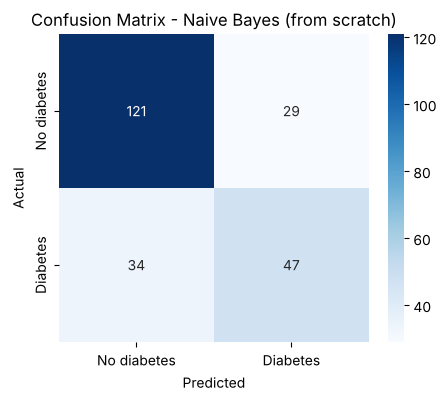

              precision    recall  f1-score   support

 No diabetes       0.78      0.81      0.79       150
    Diabetes       0.62      0.58      0.60        81

    accuracy                           0.73       231
   macro avg       0.70      0.69      0.70       231
weighted avg       0.72      0.73      0.73       231



In [8]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No diabetes', 'Diabetes'], yticklabels=['No diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Naive Bayes (from scratch)')
plt.show()

print(classification_report(y_test, y_pred, target_names=['No diabetes', 'Diabetes']))

## 10. Sample predictions with posterior probabilities

In [9]:
probs = predict_proba(model, X_test)
sample = pd.DataFrame(X_test[:10], columns=features)
sample['P(no diabetes)'] = probs[:10, 0].round(4)
sample['P(diabetes)'] = probs[:10, 1].round(4)
sample['Predicted'] = y_pred[:10]
sample['Actual'] = y_test[:10]
display(sample)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,P(no diabetes),P(diabetes),Predicted,Actual
0,3.0,130.0,78.0,23.0,79.0,28.4,0.323,34.0,0.9189,0.0811,0,1
1,4.0,109.0,64.0,44.0,99.0,34.8,0.905,26.0,0.8531,0.1469,0,1
2,11.0,143.0,94.0,33.0,146.0,36.6,0.254,51.0,0.0434,0.9566,1,1
3,4.0,144.0,82.0,32.0,125.0,38.5,0.554,37.0,0.3552,0.6448,1,1
4,8.0,105.0,100.0,36.0,125.0,43.3,0.239,45.0,0.2298,0.7702,1,1
5,2.0,99.0,52.0,15.0,94.0,24.6,0.637,21.0,0.9973,0.0027,0,0
6,10.0,162.0,84.0,29.0,125.0,27.7,0.182,54.0,0.0823,0.9177,1,0
7,5.0,111.0,72.0,28.0,125.0,23.9,0.407,27.0,0.9648,0.0352,0,0
8,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.9937,0.0063,0,0
9,0.0,107.0,76.0,29.0,125.0,45.3,0.686,24.0,0.7611,0.2389,0,0


## 11. Visualize the Gaussian class-conditional distributions
The histograms show the real data and the curves show the Gaussian distributions learned by the model for two important features.

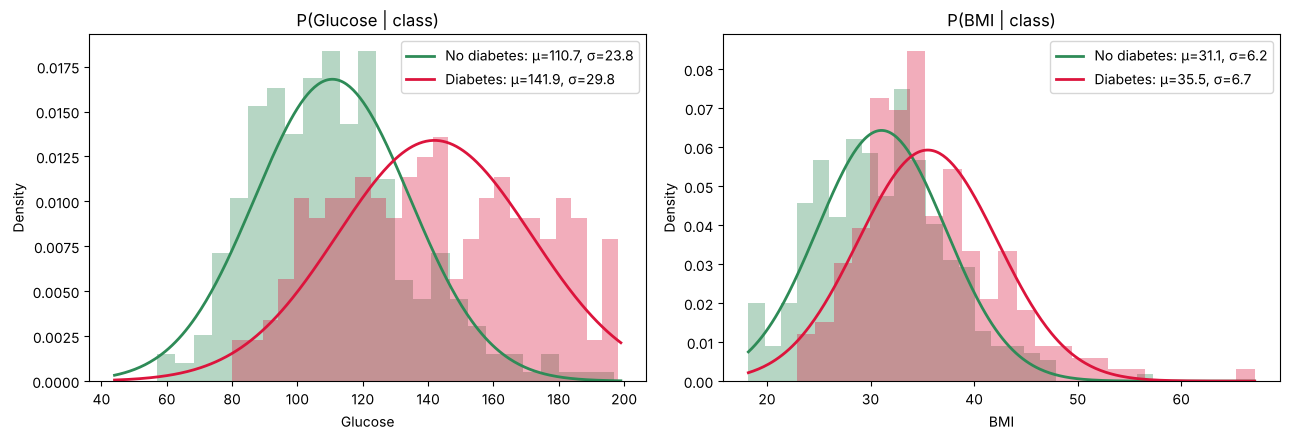

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feature in zip(axes, ['Glucose', 'BMI']):
    i = features.index(feature)
    xs = np.linspace(X[:, i].min(), X[:, i].max(), 300)
    for c, color, label in [(0, 'seagreen', 'No diabetes'), (1, 'crimson', 'Diabetes')]:
        ax.hist(X_train[y_train == c, i], bins=25, density=True, alpha=0.35, color=color)
        ax.plot(xs, gaussian_pdf(xs, model[c]['mean'][i], model[c]['std'][i]), color=color, linewidth=2,
                label=f"{label}: μ={model[c]['mean'][i]:.1f}, σ={model[c]['std'][i]:.1f}")
    ax.set_title(f'P({feature} | class)')
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Diabetic patients have clearly higher glucose levels and BMI, so these features shift the posterior probability strongly towards the *diabetes* class.

## 12. Compare with scikit-learn's GaussianNB

In [11]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)
sk_pred = gnb.predict(X_test)

print(f"Accuracy (from scratch): {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Accuracy (scikit-learn): {accuracy_score(y_test, sk_pred) * 100:.2f}%")
print(f"Both models agree on {(y_pred == sk_pred).mean() * 100:.1f}% of the test predictions")

cv_scores = cross_val_score(GaussianNB(), X, y, cv=10)
print(f"\n10-fold cross-validation accuracy (GaussianNB): {cv_scores.mean() * 100:.2f}% ± {cv_scores.std() * 100:.2f}%")

Accuracy (from scratch): 72.73%
Accuracy (scikit-learn): 72.73%
Both models agree on 100.0% of the test predictions

10-fold cross-validation accuracy (GaussianNB): 75.00% ± 3.38%


## 13. Classify a new patient

In [12]:
new_patient = pd.DataFrame([[2, 160, 75, 30, 150, 34.0, 0.6, 45]], columns=features)
p = predict_proba(model, new_patient.values)[0]
display(new_patient)
print(f"P(no diabetes) = {p[0]:.4f}, P(diabetes) = {p[1]:.4f}")
print("Prediction:", 'Diabetes' if p.argmax() == 1 else 'No diabetes')

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,160,75,30,150,34.0,0.6,45


P(no diabetes) = 0.2609, P(diabetes) = 0.7391
Prediction: Diabetes


## 14. Documentation summary
1. Loaded the Pima Indians Diabetes training data from a CSV file and explored it
2. Replaced medically invalid zero values with the column median
3. Split the data into training and test sets
4. Explained Bayes' rule, the naïve independence assumption and the Gaussian class-conditional distribution
5. Trained the classifier by estimating the prior, mean and standard deviation of each feature for each class (maximum likelihood)
6. Implemented the Gaussian probability density function and prediction using log posteriors
7. Computed the accuracy on the test set, the confusion matrix and the classification report
8. Displayed posterior probabilities and visualized the learned class-conditional distributions
9. Verified the results against scikit-learn's `GaussianNB` and ran 10-fold cross-validation
10. Classified a new patient

**Result:** The Naïve Bayesian classifier was implemented from scratch and its accuracy on the test set was computed. It gives the same predictions as scikit-learn's `GaussianNB`.